# 3F. Autoencoder - Sign MNIST Anomaly
Treat label 0 as anomaly. Train AE on remaining 23 classes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import roc_auc_score, classification_report

In [2]:
train = pd.read_csv("../datasets/FNN and CNN/Sign Language MNIST/sign_mnist_train.csv")

y_anom = (train["label"] == 0).to_numpy().astype(int)
x = train.drop(columns="label").to_numpy().astype("float32") / 255.0

x_train_norm = x[y_anom == 0]
print("normal (23 classes):", x_train_norm.shape, "anomaly (class 0):", y_anom.sum())

normal (23 classes): (26329, 784) anomaly (class 0): 1126


In [3]:
model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(784, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,192 (852.31 KB)

 Trainable params: 218,192 (852.31 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(x_train_norm, x_train_norm, epochs=5, validation_split=0.1)

Epoch 1/5
741/741 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.0174 - val_loss: 0.0108
Epoch 2/5
741/741 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0093 - val_loss: 0.0085
Epoch 3/5
741/741 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0079 - val_loss: 0.0075
Epoch 4/5
741/741 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0071 - val_loss: 0.0070
Epoch 5/5
741/741 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0067 - val_loss: 0.0065


In [5]:
recon = model.predict(x)
err = np.mean((x - recon) ** 2, axis=1)

auc = roc_auc_score(y_anom, err)
threshold = np.quantile(err[y_anom == 0], 0.95)
y_pred = (err > threshold).astype(int)

print(f"AUC: {auc:.4f}")
print(classification_report(y_anom, y_pred, target_names=["normal", "anomaly"]))

AUC: 0.6344
              precision    recall  f1-score   support
      normal       0.96      0.95      0.96     26329
     anomaly       0.09      0.12      0.10      1126
    accuracy                           0.92     27455
   macro avg       0.53      0.53      0.53     27455
weighted avg       0.93      0.92      0.92     27455


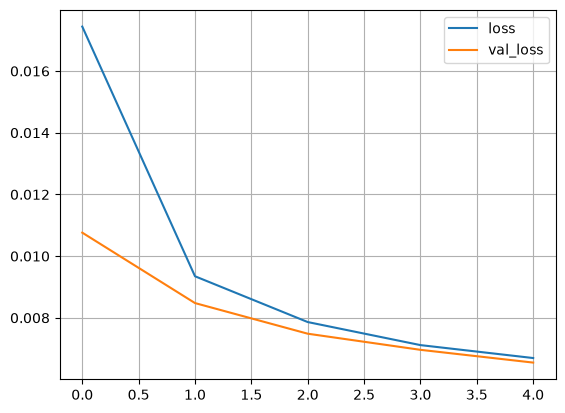

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()